Importing plotly failed. Interactive plots will not work.


--- Augmented Dickey-Fuller Test ---
ADF Statistic: -6.9427
p-value: 0.0000
Result: Data is stationary

--- Time-Series Decomposition ---


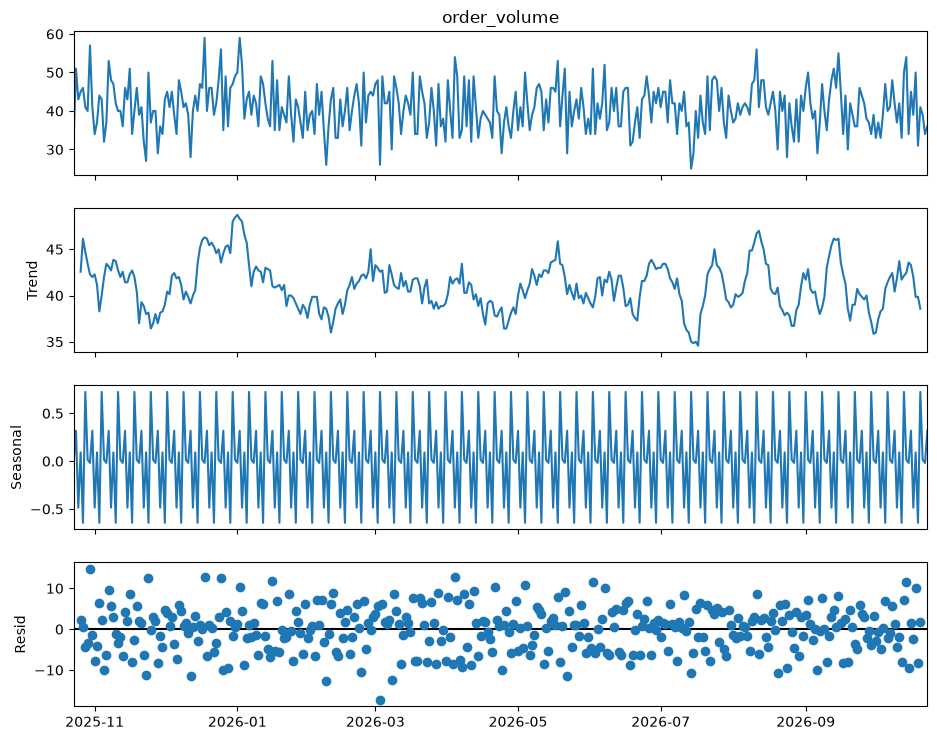

10:17:48 - cmdstanpy - INFO - Chain [1] start processing
10:17:48 - cmdstanpy - INFO - Chain [1] done processing



--- Model Comparison ---
ARIMA Test RMSE: 6.20
Prophet Test RMSE: 6.27


10:17:49 - cmdstanpy - INFO - Chain [1] start processing
10:17:49 - cmdstanpy - INFO - Chain [1] done processing


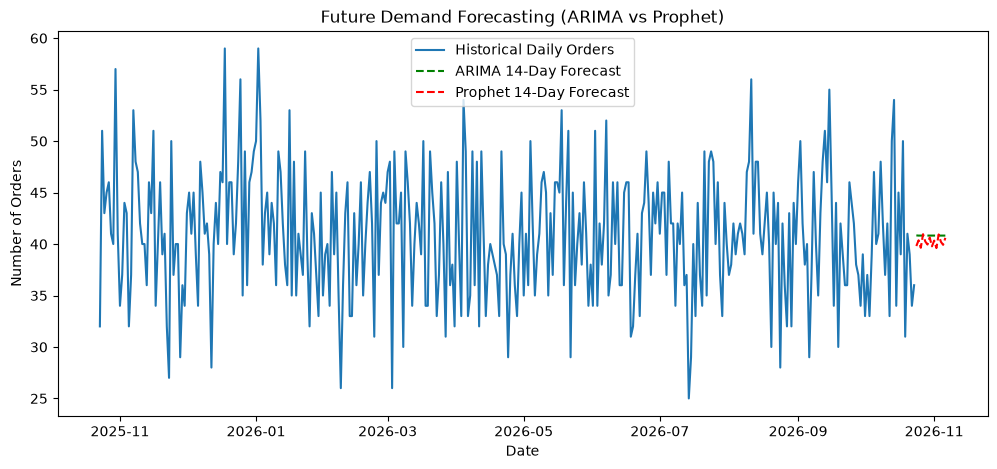

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
from prophet import Prophet
import warnings
warnings.filterwarnings('ignore')

# Part 1: Temporal Data Aggregation
orders = pd.read_csv('../data/orders.csv')
orders['order_timestamp'] = pd.to_datetime(orders['order_timestamp'])
orders.set_index('order_timestamp', inplace=True)
daily_data = orders.resample('D').size().rename('order_volume')
daily_data = daily_data.fillna(0)

# Part 2: Stationarity Testing & Decomposition
def test_stationarity(timeseries):
    print("--- Augmented Dickey-Fuller Test ---")
    adf_test = adfuller(timeseries, autolag='AIC')
    print(f"ADF Statistic: {adf_test[0]:.4f}")
    print(f"p-value: {adf_test[1]:.4f}")
    if adf_test[1] <= 0.05:
        print("Result: Data is stationary")
    else:
        print("Result: Data is non-stationary")
        
test_stationarity(daily_data)

print("\n--- Time-Series Decomposition ---")
decomposition = seasonal_decompose(daily_data, model='additive', period=7)
fig = decomposition.plot()
fig.set_size_inches(10, 8)
plt.show()

# Part 3: Data Splitting
train_size = int(len(daily_data) * 0.8)
train_data, test_data = daily_data.iloc[:train_size], daily_data.iloc[train_size:]

# Part 4: ARIMA Modeling & Evaluation
arima_model = ARIMA(train_data, order=(1, 1, 1))
fitted_arima = arima_model.fit()
arima_predictions = fitted_arima.forecast(steps=len(test_data))
arima_predictions.index = test_data.index
arima_rmse = np.sqrt(mean_squared_error(test_data, arima_predictions))

# Part 5: Prophet Modeling & Evaluation
prophet_df = daily_data.reset_index()
prophet_df.columns = ['ds', 'y']
train_prophet = prophet_df.iloc[:train_size]
test_prophet = prophet_df.iloc[train_size:]

prophet_model = Prophet(daily_seasonality=False, yearly_seasonality=False)
prophet_model.fit(train_prophet)
future_test = prophet_model.make_future_dataframe(periods=len(test_prophet))
forecast_test = prophet_model.predict(future_test)
prophet_predictions = forecast_test['yhat'].iloc[train_size:].values
prophet_rmse = np.sqrt(mean_squared_error(test_prophet['y'], prophet_predictions))

print(f"\n--- Model Comparison ---")
print(f"ARIMA Test RMSE: {arima_rmse:.2f}")
print(f"Prophet Test RMSE: {prophet_rmse:.2f}")

# Part 6: Future Forecasting (Next 14 Days)
# ARIMA Future
final_arima = ARIMA(daily_data, order=(1, 1, 1)).fit()
future_steps = 14
arima_future = final_arima.forecast(steps=future_steps)
future_dates = pd.date_range(start=daily_data.index[-1] + pd.Timedelta(days=1), periods=future_steps)
arima_future.index = future_dates

# Prophet Future
final_prophet = Prophet(daily_seasonality=False, yearly_seasonality=False).fit(prophet_df)
future_14 = final_prophet.make_future_dataframe(periods=future_steps)
prophet_future = final_prophet.predict(future_14)
prophet_future_values = prophet_future['yhat'].iloc[-future_steps:].values

plt.figure(figsize=(12, 5))
plt.plot(daily_data.index, daily_data, label='Historical Daily Orders')
plt.plot(arima_future.index, arima_future, color='green', linestyle='--', label='ARIMA 14-Day Forecast')
plt.plot(arima_future.index, prophet_future_values, color='red', linestyle='--', label='Prophet 14-Day Forecast')
plt.title('Future Demand Forecasting (ARIMA vs Prophet)')
plt.xlabel('Date')
plt.ylabel('Number of Orders')
plt.legend()
plt.show()